# 01 · EDA y preprocesado

**Grupo:** Oscar Romero Quincoces · Fernando Dapena Tauste · Daniel Garcia Lopez

**Objetivo.** Entender los datos de construcción antes de modelar y dejarlos limpios y listos para los notebooks 02–04.
Cada decisión de preprocesado sale de un hallazgo del EDA, y la métrica final es la **AUPR**.

**Cómo leer este notebook.** Cada sección sigue el mismo orden: **pregunta → figura → conclusión → impacto** en el modelado.

| Parte I · EDA | Parte II · Limpieza y preparación |
|---|---|
| 0. Setup | 12. Duplicados y conflictos de etiqueta |
| 1. ¿Qué tenemos? | 13. Transformaciones |
| 2. ¿Cuánto fraude hay? | 14. Escalado |
| 3. ¿Hay duplicados? | 15. Folds sin fuga |
| 4. ¿Cómo se distribuye cada variable? | 16. Exportar datos preparados |
| 5. ¿Qué variables separan el fraude? | Conectores |
| 6. ¿Qué pasa con `Amount`? | |
| 7. ¿Están correlacionadas? | |
| 8. ¿Se ve estructura multivariante? | |
| 9. ¿Los fraudes están en las colas? | |
| 10. ¿Producción se parece a construcción? | |
| 11. Conclusiones del EDA | |

In [1]:
# ============================================================
# CELDA DE CARGA DEL 01 — NO MODIFICAR
# Lee los CSV originales y crea el split fijo del profesor. 02–04 y 99 usan la celda común v2,
# que lee el CSV que exporta este notebook; metrics() y plot_pr() son idénticas en ambas. Ver D-0.1.
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold  # StratifiedKFold: validación adversarial (§10)
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

pd.options.display.max_columns = None
SEED = 42
DATA_DIR = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data"
OUTPUT_DIR = DATA_DIR / "output"

df_const = pd.read_csv(DATA_DIR / "credit_card_construction.csv")
df_prod = pd.read_csv(DATA_DIR / "credit_card_production.csv").drop(columns="Class")
FEATURES = [c for c in df_const.columns if c != "Class"]

# Split del notebook de partida del profesor: 70/30 estratificado, random_state=42
df_train, df_test = train_test_split(df_const, test_size=0.3, random_state=SEED, stratify=df_const["Class"])
X_train, y_train = df_train[FEATURES], df_train["Class"]
X_test, y_test = df_test[FEATURES], df_test["Class"]

def metrics(y_true, scores):
    """Métrica oficial: AUPR (average_precision_score). Mayor score = más fraude."""
    return {"aupr": average_precision_score(y_true, scores), "roc_auc": roc_auc_score(y_true, scores)}

def plot_pr(y_true, scores_by_model, ax=None):
    ax = ax or plt.subplots(figsize=(6, 5))[1]
    for name, s in scores_by_model.items():
        p, r, _ = precision_recall_curve(y_true, s)
        ax.plot(r, p, label=f"{name} (AUPR={average_precision_score(y_true, s):.3f})")
    ax.axhline(np.mean(y_true), ls="--", c="grey", label="aleatorio")
    ax.set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall")
    ax.legend()
    return ax

print(df_const.shape, df_prod.shape, f"fraude train={y_train.mean():.4%} test={y_test.mean():.4%}")

(170884, 22) (113923, 21) fraude train=0.1722% test=0.1736%


## 0. Setup

Librerías y rutas propias de este notebook. Los datos (`df_const`, `df_prod`, `FEATURES`) y `metrics()` vienen de la celda de carga.

Paleta fija (**gris = normal, rojo = fraude**), una muestra ligera `viz` para pintar y tres utilidades que se reutilizan en todo el notebook.

In [2]:
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook", rc={"figure.figsize": (8, 4.5), "axes.titleweight": "bold"})
C = {0: "#9e9e9e", 1: "#d62728"}          # gris = normal, rojo = fraude
LBL = {0: "normal", 1: "fraude"}

In [3]:
# muestra para gráficos: 20.000 normales + todos los fraudes
viz = pd.concat([df_const[df_const.Class == 0].sample(20_000, random_state=SEED), df_const[df_const.Class == 1]])
resumen = pd.DataFrame(index=FEATURES)    # métricas por variable; la Parte II lo exporta
viz.Class.value_counts().rename(LBL)

Class
normal    20000
fraude      295
Name: count, dtype: int64

In [4]:
def kde_grid(df, cols, ncols=5):
    """Densidad por clase (cada una normalizada); eje x recortado a p0,2–p99,8 para ver la forma."""
    nrows = -(-len(cols) // ncols); fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.4 * nrows))
    for ax, col in zip(axes.flat, cols):
        sns.kdeplot(data=df, x=col, hue="Class", palette=C, common_norm=False, fill=True, alpha=.35, ax=ax, legend=False)
        ax.set(title=col, xlabel="", ylabel="", yticks=[], xlim=df[col].quantile([.002, .998]).tolist())
    for ax in axes.flat[len(cols):]: ax.axis("off")
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C[k]) for k in C], labels=list(LBL.values()), loc="upper right"); fig.tight_layout()

In [5]:
def barh_rank(s, title, ref=None, fmt="{:.3f}", color=C[1]):
    """Barras horizontales ordenadas (mayor arriba) con el valor anotado; ref = línea vertical opcional."""
    s = s.sort_values()
    ax = s.plot.barh(color=color, figsize=(7, 0.3 * len(s) + 1), title=title)
    ax.bar_label(ax.containers[0], labels=[fmt.format(v) for v in s], padding=2, fontsize=8)
    if ref is not None: ax.axvline(ref, ls="--", c="k", lw=1)
    return ax

In [6]:
def uni_scores(X, y):
    """Por variable: AUPR univariante orientado max(AUPR(x), AUPR(-x)) y KS fraude vs normal."""
    y = np.asarray(y)
    return pd.DataFrame({c: {"aupr_uni": max(average_precision_score(y, X[c]), average_precision_score(y, -X[c])),
                             "ks": stats.ks_2samp(X[c][y == 1], X[c][y == 0]).statistic} for c in X}).T

---
# PARTE I · EDA

Diez preguntas sobre los datos. Las respuestas deciden la limpieza de la Parte II y qué conviene probar en 02–04.

## 1. ¿Qué tenemos?

**Qué miramos y por qué.** Tamaño, tipos, nulos y rangos de construcción y producción. Antes de modelar hay que saber si los datos son lo que creemos que son.

In [7]:
# ficha comparada de los dos ficheros (producción no trae Class)
ficha = lambda d: {"filas": len(d), "columnas": d.shape[1], "nulos": int(d.isna().sum().sum()),
                   "duplicados": int(d.duplicated().sum()), "memoria_MB": round(d.memory_usage(deep=True).sum() / 1e6, 1),
                   "Amount_min": d.Amount.min(), "Amount_max": d.Amount.max()}
pd.DataFrame.from_dict({"construcción": ficha(df_const), "producción": ficha(df_prod)}, orient="index")

,filas,columnas,nulos,duplicados,memoria_MB,Amount_min,Amount_max
construcción,170884,22,0,4167,30.1,0.0,29484.80
producción,113923,21,0,2109,19.1,0.0,38536.74


Resumen estadístico de construcción (todas las variables numéricas):

In [8]:
df_const.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
X1,170884.0,0.59,390.92,-11282.0,-184.00,4.0,264.00,490.0
X2,170884.0,-0.05,330.50,-14544.0,-120.00,14.0,162.00,4294.0
X3,170884.0,0.29,302.08,-6594.0,-178.00,36.0,206.00,1876.0
X4,170884.0,-0.10,282.57,-1136.0,-170.00,-4.0,150.00,3344.0
X5,170884.0,0.28,270.76,-6418.0,-138.00,-12.0,122.00,6960.0
X6,170884.0,0.05,263.93,-5232.0,-154.00,-54.0,80.00,4278.0
X7,170884.0,0.01,241.11,-8302.0,-112.00,8.0,114.00,6860.0
X8,170884.0,0.22,238.59,-14644.0,-42.00,4.0,66.00,4002.0
X9,170884.0,-0.02,219.37,-2686.0,-128.00,-10.0,120.00,3118.0
X10,170884.0,-0.08,216.79,-4880.0,-106.00,-18.0,92.00,4750.0


> **Conclusión:** 170.884 × 22 en construcción y 113.923 × 21 en producción, **0 nulos**. Las `X` son enteras y centradas (std 152–391) con rangos enormes (X8 hasta −14.644). `Amount` va de 0 a 29.485 en construcción, pero hasta 38.537 en producción. → **Impacto:** no hace falta imputar; las `X` ya vienen centradas (tipo PCA) pero `Amount` está en otra escala, así que escalado obligatorio para métodos de distancia (Parte II, §14).

## 2. ¿Cuánto fraude hay?

**Qué miramos y por qué.** El balance de `Class`. Con un 0,17 % de positivos, la accuracy no sirve y el ROC engaña. Por eso medimos **AUPR**: su valor aleatorio es la propia prevalencia.

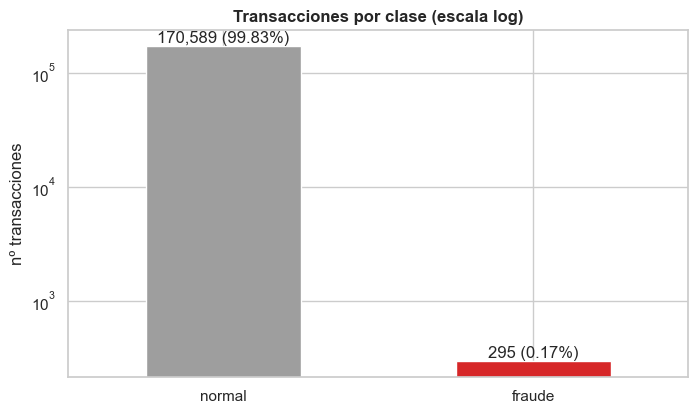

In [9]:
n = df_const.Class.value_counts().rename(LBL)
ax = n.plot.bar(color=[C[0], C[1]], rot=0, logy=True, title="Transacciones por clase (escala log)")
ax.bar_label(ax.containers[0], labels=[f"{v:,} ({v / n.sum():.2%})" for v in n])
ax.set(xlabel="", ylabel="nº transacciones");

In [10]:
# un modelo que dice "todo normal" acierta casi siempre y no detecta ningún fraude
prev = df_const.Class.mean()
f"AUPR aleatorio = prevalencia = {prev:.4f} · accuracy de predecir siempre 'normal' = {1 - prev:.2%}"

"AUPR aleatorio = prevalencia = 0.0017 · accuracy de predecir siempre 'normal' = 99.83%"

> **Conclusión:** **295 fraudes (0,17 %)**. Decir siempre "normal" da un 99,83 % de accuracy, que no sirve para nada. El AUPR aleatorio es **0,0017** (el GMM del profesor da 0,567 en el test del split común, ver `docs/teoria/notebook_partida.md`). → **Impacto:** métrica AUPR en todos los notebooks (referencia aleatoria ≈ prevalencia); split y CV estratificados; con tan pocos fraudes, la varianza entre folds será alta (02–04).

## 3. ¿Hay duplicados?

**Qué miramos y por qué.** Filas idénticas, cuántas son fraude y si hay copias con etiquetas distintas. Si una copia cae en train y otra en test, hay **fuga** y la AUPR de la CV sale optimista. Los fraudes duplicados además dejan de ser "raros" para los detectores de densidad.

In [11]:
# hash por fila: rápido y permite comparar entre ficheros
h_full = pd.util.hash_pandas_object(df_const, index=False)              # fila completa (X + Class)
h_x = pd.util.hash_pandas_object(df_const[FEATURES], index=False)       # solo X
h_prod = pd.util.hash_pandas_object(df_prod[FEATURES], index=False)
n_clases = df_const.Class.groupby(h_x.values).nunique()                 # nº de etiquetas por grupo de X idénticas

In [12]:
pd.Series({"duplicados en construcción (fila completa)": h_full.duplicated().sum(),
           "duplicados entre fraudes": h_full[df_const.Class == 1].duplicated().sum(),
           "grupos de X idénticas con Class distinta": (n_clases > 1).sum(),
           "duplicados en producción": h_prod.duplicated().sum(),
           "filas de producción idénticas a alguna de construcción": h_prod.isin(h_x).sum()}, name="nº").to_frame()

,nº
duplicados en construcción (fila completa),4167
duplicados entre fraudes,10
grupos de X idénticas con Class distinta,0
duplicados en producción,2109
filas de producción idénticas a alguna de construcción,4314


El split común no agrupa duplicados: ¿cuántas filas de test tienen una copia exacta en train?

In [13]:
en_train = h_x.loc[df_test.index].isin(h_x.loc[df_train.index])
pd.Series({"filas de test con copia en train": en_train.sum(), "fraudes de test con copia en train": (en_train & (y_test == 1)).sum(),
           "fraudes en test": int(y_test.sum())}, name="nº").to_frame()

,nº
filas de test con copia en train,1643
fraudes de test con copia en train,5
fraudes en test,89


> **Conclusión:** **4.167 filas duplicadas** en construcción (10 entre fraudes), **0 conflictos de etiqueta**, 2.109 duplicadas en producción y **4.314 filas de producción idénticas a alguna de construcción**. Además, **1.643 filas de test (5 de los 89 fraudes) tienen copia en train**, una proporción parecida a la de producción frente a construcción (3,2 % frente a 3,8 %). En 02–04 se reporta el AUPR de test con y sin esas filas (flag `dup_en_train`). → **Impacto:** asignar `group_id` a filas idénticas y usar `StratifiedGroupKFold` para que las copias no crucen train/validación (Parte II, §12 y §15); producción se puntúa entera, sin deduplicar.

## 4. ¿Cómo se distribuye cada variable?

**Qué miramos y por qué.** Histogramas, asimetría y curtosis de `X1..X20` y `Amount`. "Pintar el histograma antes de asumir una gaussiana": el GMM y Mahalanobis dependen de esa forma.

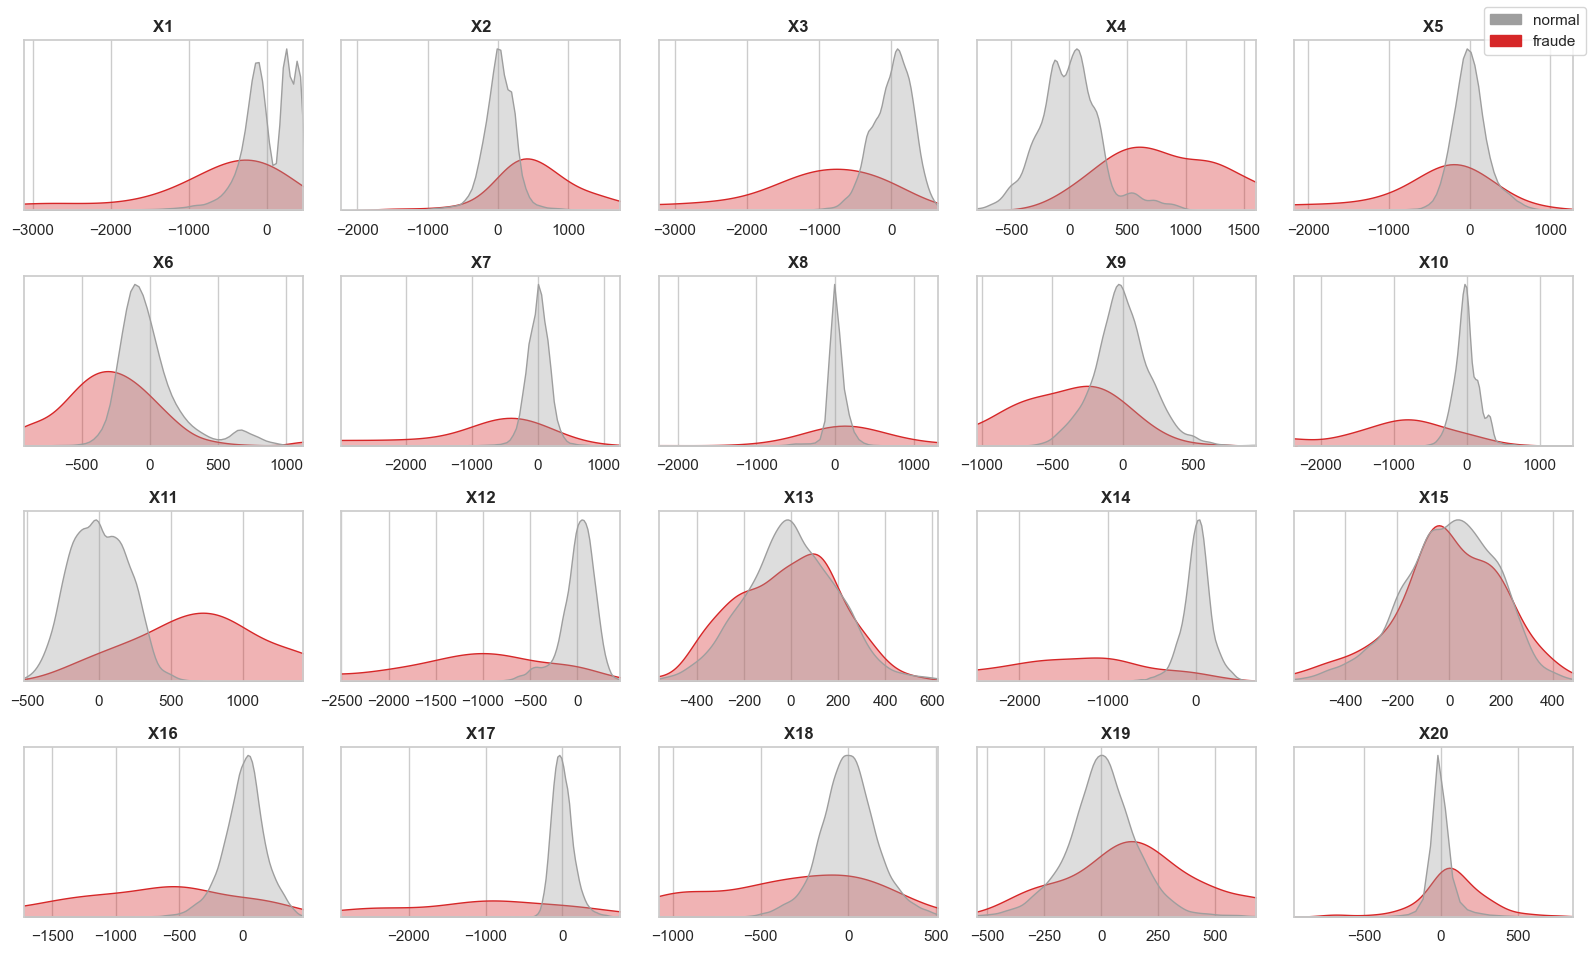

In [14]:
kde_grid(viz, [f for f in FEATURES if f != "Amount"])

In [15]:
# forma de cada variable: asimetría y curtosis (exceso) sobre construcción completa
resumen["skew"] = df_const[FEATURES].skew()
resumen["kurtosis"] = df_const[FEATURES].kurt()
resumen[["skew", "kurtosis"]].sort_values("kurtosis", ascending=False).round(2)

,skew,kurtosis
Amount,13.39,465.63
X8,-8.99,253.54
X20,-1.11,185.18
X2,-4.74,100.93
X17,-3.95,97.98
X7,-1.28,81.59
X5,-0.03,42.23
X1,-3.32,34.38
X10,1.22,32.22
X14,-2.12,25.49


> **Conclusión:** **Colas muy pesadas**: curtosis de Amount 466, X8 254, X20 185, X2 101 y X17 98. Solo X4, X11, X13, X15, X18 y X19 son casi gaussianas. Las densidades del fraude son mucho más anchas y desplazadas que las normales. → **Impacto:** probar transformaciones (`log1p`, quantile/rank-gauss) antes de GMM/Mahalanobis y decidir por AUPR en CV (§13; `02_baselines_no_supervisados`). El escalador solo afecta a euclídea y kNN: Mahalanobis no cambia con escalados lineales.

## 5. ¿Qué variables separan el fraude?

**Qué miramos y por qué.** Las distribuciones de fraude y no fraude por variable, ordenadas por capacidad de separación. Las variables irrelevantes degradan los métodos de distancia y densidad, así que esto orienta la selección de variables.

In [16]:
# solo train: las etiquetas del test fijo no se miran para decidir variables
u = uni_scores(X_train, y_train)
resumen[u.columns] = u

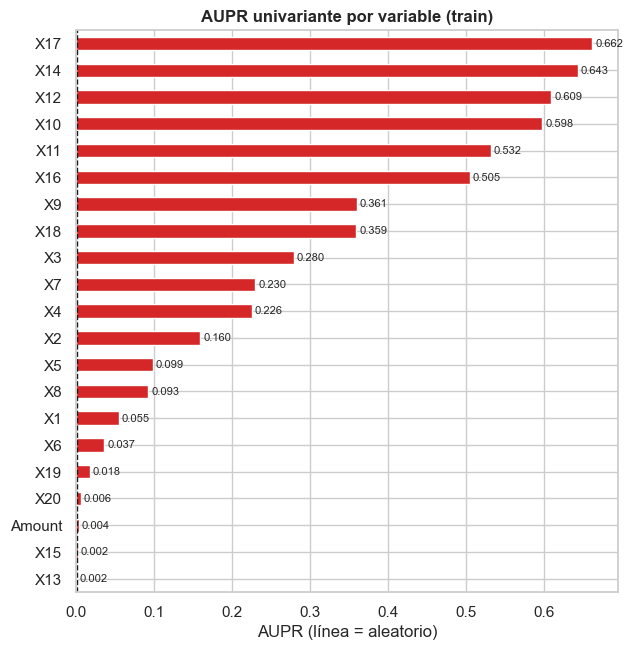

In [17]:
barh_rank(resumen.aupr_uni, "AUPR univariante por variable (train)", ref=y_train.mean())
plt.gca().set(xlabel="AUPR (línea = aleatorio)");

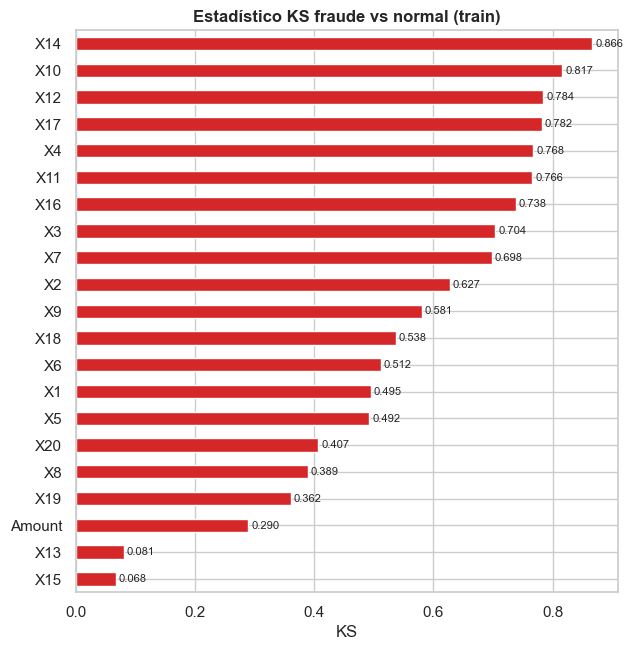

In [18]:
barh_rank(resumen.ks, "Estadístico KS fraude vs normal (train)")
plt.gca().set(xlabel="KS");

> **Conclusión:** Calculado solo con train: **X17 (0,662), X14 (0,643), X12 (0,609) y X10 (0,598)** de AUPR univariante, ya al nivel del GMM. Le siguen X11 (0,53) y X16 (0,51). El resto es débil (≤ 0,36). Ojo: X4 tiene KS alto pero AUPR bajo, y `Amount` casi aleatorio. Desplazan la masa sin poner el fraude arriba del ranking, que es lo que mide la AUPR. → **Impacto:** las variables con AUPR ≈ aleatorio son candidatas a eliminarse o ponderarse en métodos de distancia/densidad; comparar en 02–04 "todas" vs "top-k" variables.

## 6. ¿Qué pasa con `Amount`?

**Qué miramos y por qué.** Su escala, su cola, los ceros y su relación con el fraude, en bruto y con `log1p`. Transformar una variable **cambia qué es outlier** (teoria/01).

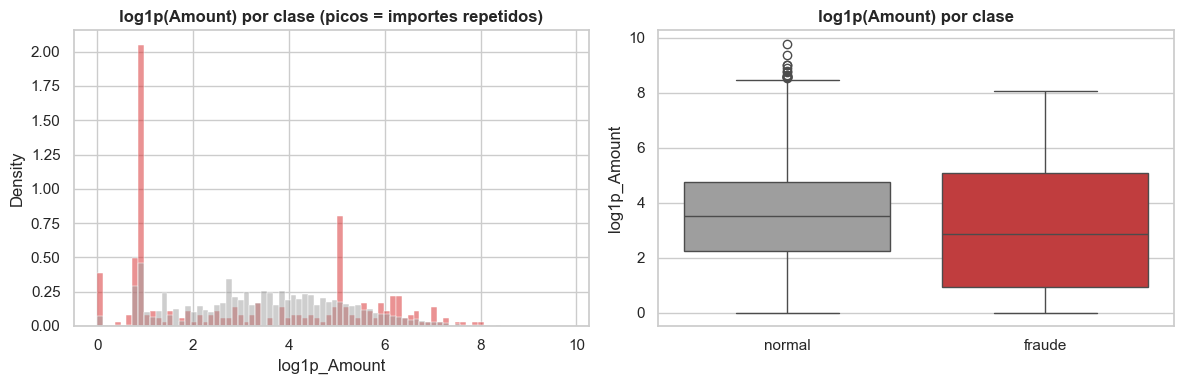

In [19]:
d = viz.assign(log1p_Amount=np.log1p(viz.Amount), clase=viz.Class.map(LBL))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=d, x="log1p_Amount", hue="Class", palette=C, stat="density", common_norm=False, bins=80, ax=axes[0], legend=False)
axes[0].set(title="log1p(Amount) por clase (picos = importes repetidos)")
sns.boxplot(data=d, x="clase", y="log1p_Amount", hue="clase", palette={LBL[k]: C[k] for k in C}, ax=axes[1])
axes[1].set(title="log1p(Amount) por clase", xlabel=""); fig.tight_layout()

In [20]:
q95 = lambda s: s.quantile(.95)
pct_ceros = lambda s: (s == 0).mean() * 100
df_const.groupby(df_const.Class.map(LBL)).Amount.agg(mediana="median", p95=q95, máx="max", pct_ceros=pct_ceros).round(2)

,mediana,p95,máx,pct_ceros
Class,,,,
fraude,16.50,802.53,3188.8,4.07
normal,33.03,549.55,29484.8,0.63


Los picos del histograma: importes exactos que se repiten en el fraude.

In [21]:
top = df_const[df_const.Class == 1].Amount.value_counts().head(5)
pct = lambda k: [100 * (df_const[df_const.Class == k].Amount == v).mean() for v in top.index]
pd.DataFrame({"n_fraudes": top.values, "%_fraudes": pct(1), "%_normales": pct(0)}, index=top.index).round(2)

,n_fraudes,%_fraudes,%_normales
Amount,,,
1.50,72,24.41,4.77
149.98,18,6.10,0.11
1.14,12,4.07,1.06
0.00,12,4.07,0.63
1.16,6,2.03,0.50


> **Conclusión:** Mediana del fraude **16,5 frente a 33,0** y p95 **802 frente a 550**, pero el fraude nunca pasa de **3.189** (los normales llegan a 29.485). La señal está en **importes exactos**: 1,50 es el 24 % de los fraudes (4,8 % de los normales) y 149,98 el 6 % (0,1 %). Por eso un score monótono en `Amount` no sirve. → **Impacto:** `log1p(Amount)` en distancia/densidad (§13). `Amount` no es monótono con el fraude: hay que dejar a los árboles de `03_supervisados` que aprovechen los importes exactos, sin binarizarlos a mano.

## 7. ¿Están correlacionadas?

**Qué miramos y por qué.** La matriz de correlaciones, global y por clase. Basta un par de variables correladas para que la euclídea "ordene mal los puntos" frente a Mahalanobis (teoria/01, §6). Además, si el fraude tiene su propia estructura de correlación, es una anomalía *dependiente*.

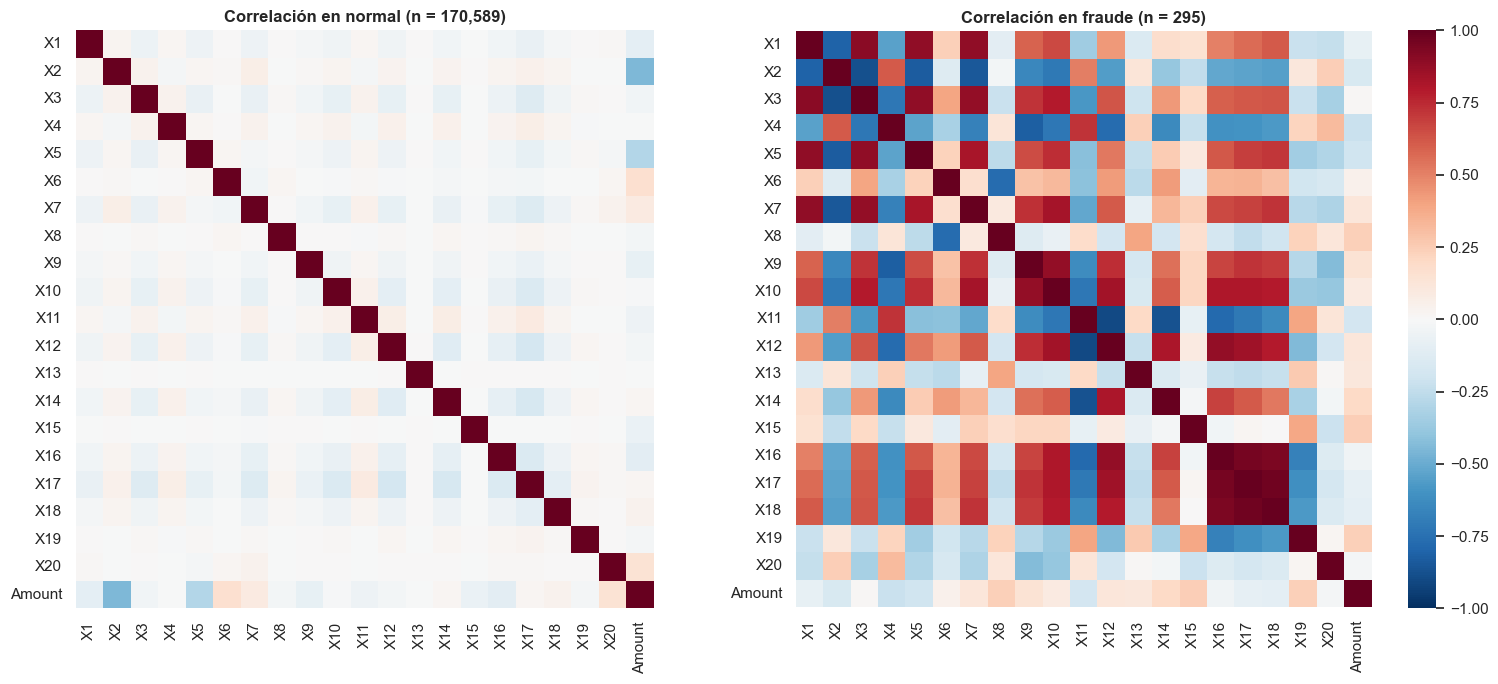

In [22]:
# Amount con log1p para que su cola larga no domine la correlación; misma escala de color en ambas clases
Z = df_const[FEATURES].assign(Amount=np.log1p(df_const.Amount))
corr = {k: Z[df_const.Class == k].corr() for k in (0, 1)}
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, k in zip(axes, (0, 1)):
    sns.heatmap(corr[k], cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, cbar=k == 1, xticklabels=True, yticklabels=True, ax=ax)
    ax.set_title(f"Correlación en {LBL[k]} (n = {(df_const.Class == k).sum():,})")
fig.tight_layout()

La correlación absoluta media por clase (0 = incorreladas) y los pares más correlados en los normales.

In [23]:
off = ~np.eye(len(FEATURES), dtype=bool)
media = pd.Series({LBL[k]: np.abs(corr[k].values[off]).mean() for k in (0, 1)}, name="|corr| media").round(3)
pares = corr[0].where(np.triu(off)).stack().abs().nlargest(3).round(2).rename("pares más correlados (normales)")
display(media, pares)

normal    0.036
fraude    0.415
Name: |corr| media, dtype: float64

X2   Amount    0.45
X5   Amount    0.29
X12  X17       0.17
Name: pares más correlados (normales), dtype: float64

> **Conclusión:** Los normales están casi incorrelados en media (**0,036**), pero hay pares concretos fuertes (**X2–Amount 0,45**, X5–Amount 0,29). Los fraudes están muy correlados (**0,415**): se mueven juntos en una dirección (anomalía *dependiente*). → **Impacto:** en `02_baselines_no_supervisados`, Mahalanobis o GMM con covarianza `full`, no la euclídea (en test, Mahalanobis da 0,58, §9; la euclídea da 0,27 según `teoria/01`, Parte A, y no se recalcula aquí).

## 8. ¿Se ve estructura multivariante?

**Qué miramos y por qué.** Proyecciones 2D (PCA, t-SNE/UMAP) coloreadas por `Class`. "Si algo se puede visualizar, se visualiza". El **tipo de anomalía** (global, local o agrupada) pesa más que el método que elijamos.

PCA ajustado solo en los normales estandarizados (Amount con log1p) y aplicado a la muestra `viz`.

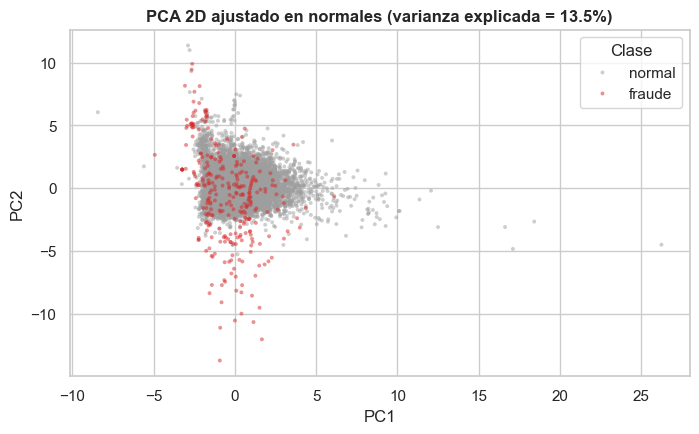

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
sc = StandardScaler().fit(Z[df_const.Class == 0])
pca = PCA(n_components=2, random_state=SEED).fit(sc.transform(Z[df_const.Class == 0]))
Zv = sc.transform(viz[FEATURES].assign(Amount=np.log1p(viz.Amount)))
P = pd.DataFrame(pca.transform(Zv), columns=["PC1", "PC2"], index=viz.index)
P["Clase"] = viz.Class.map(LBL)        # viz tiene los normales primero → los fraudes se pintan encima
ax = sns.scatterplot(data=P, x="PC1", y="PC2", hue="Clase", palette={LBL[k]: C[k] for k in C}, s=8, alpha=.5, linewidth=0)
ax.set_title(f"PCA 2D ajustado en normales (varianza explicada = {pca.explained_variance_ratio_.sum():.1%})");

Las 4 variables con mayor AUPR univariante (sección 5), por parejas.

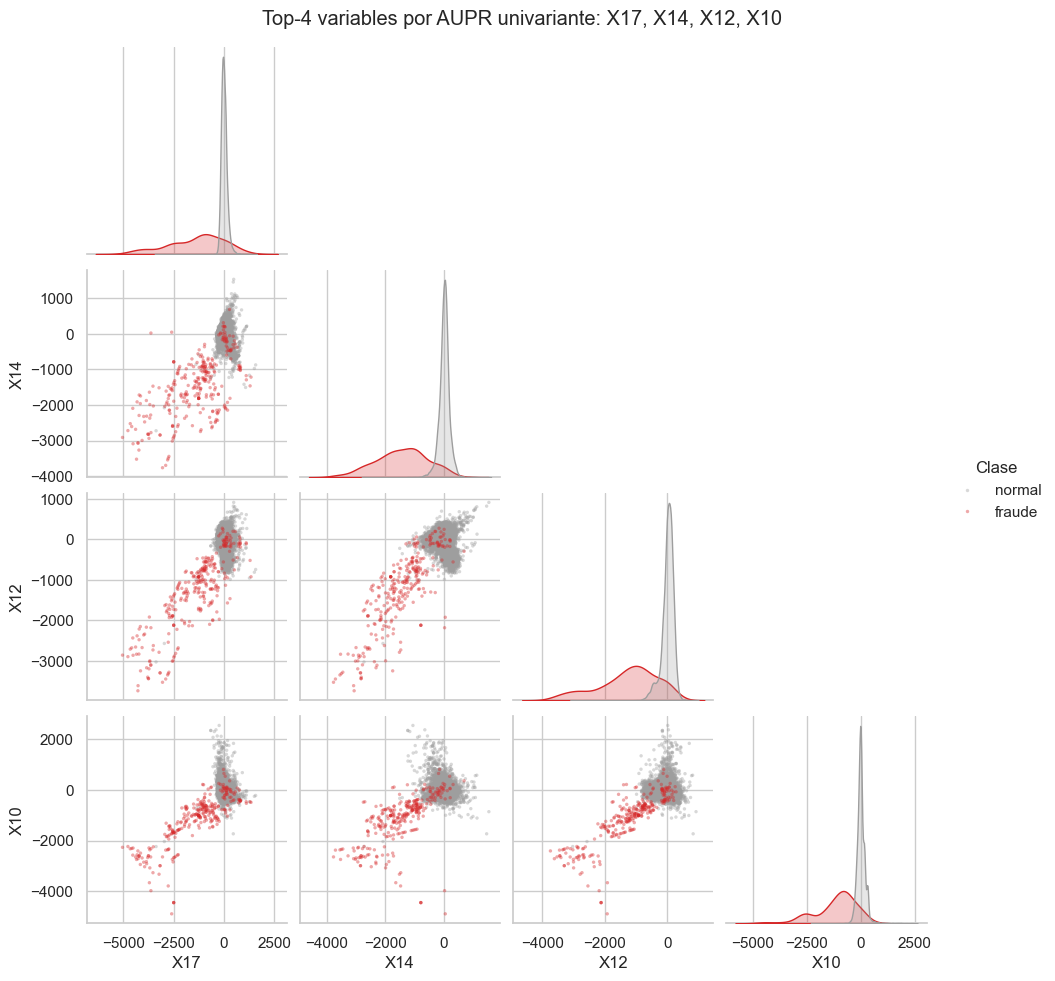

In [25]:
top4 = resumen["aupr_uni"].nlargest(4).index.tolist()
pal = {LBL[k]: C[k] for k in C}
g = sns.pairplot(viz[top4].assign(Clase=viz.Class.map(LBL)), hue="Clase", palette=pal, corner=True, height=2.4,
                 plot_kws=dict(s=6, alpha=.4, linewidth=0), diag_kws=dict(common_norm=False))
g.figure.suptitle(f"Top-4 variables por AUPR univariante: {', '.join(top4)}", y=1.02);

> **Conclusión:** La PCA de los normales (13,5 % de varianza) apenas separa: los fraudes se esparcen a lo largo de PC2. En el top-4, los fraudes forman una **cola diagonal** (X17, X14, X12 y X10 negativos a la vez). → **Impacto:** la anomalía es **global y agrupada**: en `02_baselines_no_supervisados` van primero los detectores globales (Mahalanobis, GMM, Isolation Forest) y después LOF. `03_supervisados` puede aprender esa dirección.

## 9. ¿Los fraudes están en las colas?

**Qué miramos y por qué.** Qué fracción de fraudes cae fuera de los percentiles extremos de cada variable o de una distancia global. Si están en las colas, un detector de rareza funciona. Si están mezclados con lo normal, hace falta un modelo supervisado.

In [26]:
# z con media/std de los NORMALES DE TRAIN (Amount con log1p); % de puntos con |z| > 3 por clase
Z0 = Z.loc[df_train.index][y_train == 0]
mu, sd = Z0.mean(), Z0.std()
out3 = (Z - mu).abs().div(sd) > 3
resumen["pct_3sigma_normal"] = 100 * out3[df_const.Class == 0].mean()
resumen["pct_3sigma_fraude"] = 100 * out3[df_const.Class == 1].mean()
resumen[["pct_3sigma_normal", "pct_3sigma_fraude"]].sort_values("pct_3sigma_fraude", ascending=False).round(2).T

,X14,X17,X12,X10,X16,X11,X3,X4,X7,X18,X9,X5,X2,X1,X8,X19,X6,X20,X15,X13,Amount
pct_3sigma_normal,1.31,1.11,1.52,1.18,0.78,0.16,0.67,1.08,1.27,0.58,0.76,1.09,1.47,1.28,1.44,1.15,1.63,1.63,0.43,0.41,0.05
pct_3sigma_fraude,84.41,80.00,76.27,70.51,63.39,60.68,56.95,48.81,47.80,43.73,32.88,31.53,28.81,26.44,23.05,13.56,11.86,7.80,1.69,0.68,0.00


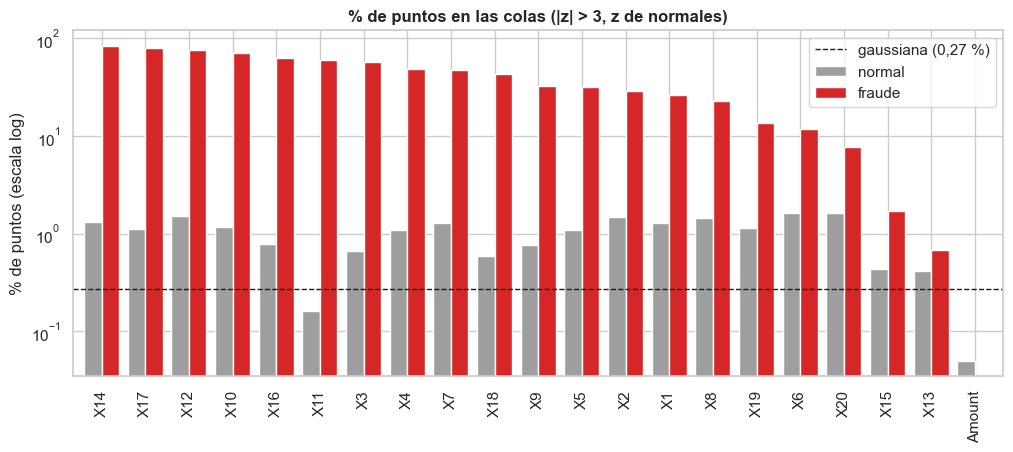

In [27]:
t = resumen[["pct_3sigma_normal", "pct_3sigma_fraude"]].sort_values("pct_3sigma_fraude", ascending=False).set_axis(["normal", "fraude"], axis=1)
ax = t.plot.bar(color=[C[0], C[1]], figsize=(12, 4.5), width=.8, logy=True, title="% de puntos en las colas (|z| > 3, z de normales)")
ax.axhline(0.27, ls="--", c="k", lw=1, label="gaussiana (0,27 %)")
ax.set(ylabel="% de puntos (escala log)", xlabel="")
ax.legend();

Distancia global: Mahalanobis ajustada con los **normales de train** (Amount con log1p); AUPR medido en test.

In [28]:
from sklearn.covariance import EmpiricalCovariance
d_mah = pd.Series(np.sqrt(EmpiricalCovariance().fit(Z0).mahalanobis(Z)), index=Z.index)   # sqrt: .mahalanobis() da d²
p99 = d_mah.loc[Z0.index].quantile(.99)
pct_p99 = 100 * (d_mah[df_const.Class == 1] > p99).mean()     # los fraudes no entran en el ajuste: se usan los 295
pd.Series({"p99 normales train": p99, "% fraudes > p99": pct_p99,
           "AUPR Mahalanobis (test)": metrics(y_test, d_mah.loc[df_test.index])["aupr"]}).round(3)

p99 normales train         11.612
% fraudes > p99            83.390
AUPR Mahalanobis (test)     0.580
dtype: float64

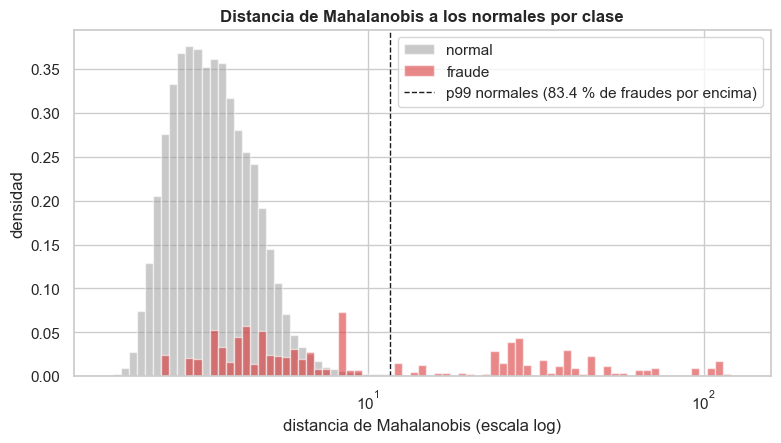

In [29]:
bins = np.logspace(np.log10(d_mah.min()), np.log10(d_mah.max()), 80)
fig, ax = plt.subplots(figsize=(9, 4.5))
for k in (0, 1):
    ax.hist(d_mah[df_const.Class == k], bins=bins, density=True, alpha=.55, color=C[k], label=LBL[k])
ax.axvline(p99, ls="--", c="k", lw=1, label=f"p99 normales ({pct_p99:.1f} % de fraudes por encima)")
ax.set(xscale="log", xlabel="distancia de Mahalanobis (escala log)", ylabel="densidad", title="Distancia de Mahalanobis a los normales por clase")
ax.legend();

> **Conclusión:** Con |z| > 3 (z de los normales de train) quedan fuera **X14 84 %, X17 80 %, X12 76 % y X10 71 %** de los fraudes, frente a ≈ 1 % de los normales. El **83 %** de los fraudes supera el p99 de Mahalanobis, cuyo AUPR en test es **0,580**. El histograma es bimodal: ~1 de cada 6 fraudes está dentro de la nube. → **Impacto:** un detector global recupera ~83 % de los fraudes con un 1 % de falsas alarmas (≈ 1.700 normales frente a ≈ 245 fraudes, precisión ≈ 13 %), y por eso su AUPR se queda en ~0,6. Los fraudes de dentro de la nube los tiene que recuperar `03_supervisados` o `04_hibrido_y_ensemble`. No recortar outliers: son la señal.

## 10. ¿Producción se parece a construcción?

**Qué miramos y por qué.** Las distribuciones por variable (KS) y la validación adversarial (los duplicados entre ficheros ya se midieron en §3). El data shift "va a pasar mucho en la práctica", y la AUPR que cuenta es la de producción.

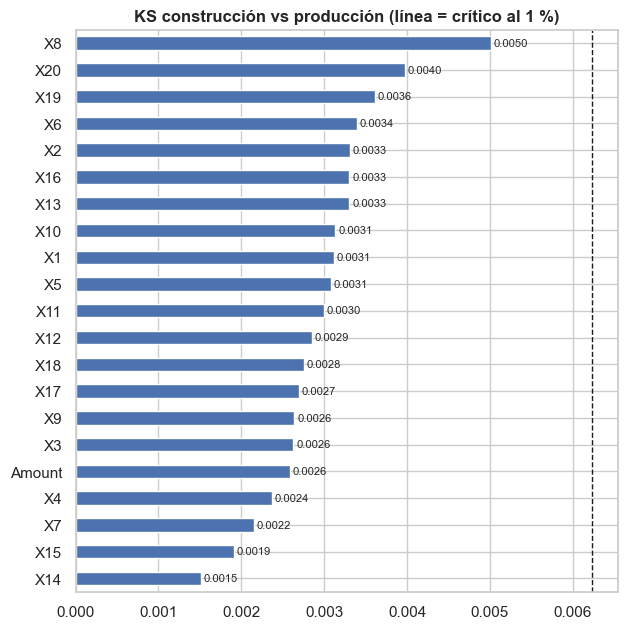

In [30]:
# KS por variable entre construcción y producción; ref = valor crítico KS al 1 % para estos tamaños
n, m = len(df_const), len(df_prod)
resumen["ks_shift"] = pd.Series({c: stats.ks_2samp(df_const[c], df_prod[c]).statistic for c in FEATURES})
barh_rank(resumen["ks_shift"], "KS construcción vs producción (línea = crítico al 1 %)",
          ref=1.63 * np.sqrt((n + m) / (n * m)), fmt="{:.4f}", color="#4c72b0");

Validación adversarial: ¿un clasificador distingue construcción (0) de producción (1)? AUC ≈ 0,5 = sin shift.

In [31]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
adv = pd.concat([df_const[FEATURES].sample(50_000, random_state=SEED), df_prod[FEATURES].sample(50_000, random_state=SEED)])
y_adv = np.r_[np.zeros(50_000), np.ones(50_000)]
cv_adv = StratifiedKFold(5, shuffle=True, random_state=SEED)
p_adv = cross_val_predict(HistGradientBoostingClassifier(random_state=SEED), adv, y_adv, cv=cv_adv, method="predict_proba")[:, 1]
auc_adv = roc_auc_score(y_adv, p_adv)
f"AUC adversarial (CV 5, 50.000 + 50.000 filas) = {auc_adv:.3f}"

'AUC adversarial (CV 5, 50.000 + 50.000 filas) = 0.496'

> **Conclusión:** **No hay data shift**: el KS máximo es 0,005 (X8), por debajo del crítico al 1 %, y la validación adversarial da **AUC 0,496**. Lo único distinto es el máximo de `Amount` (38.537 en producción). → **Impacto:** la AUPR del test interno es una estimación fiable de la de producción, y el preprocesado se ajusta solo en construcción. Para el `Amount` fuera de rango de producción, usar `log1p` y escaladores que no recorten.

## 11. Conclusiones del EDA

Cada hallazgo se traduce en una decisión y en el notebook donde se aplica (02 = `02_baselines_no_supervisados`, 03 = `03_supervisados`, 04 = `04_hibrido_y_ensemble`, 99 = `99_ENTREGA`).

| Hallazgo | Evidencia | Decisión | Afecta a |
|---|---|---|---|
| Desbalanceo extremo | 295 fraudes (0,17 %); AUPR aleatorio 0,0017 | AUPR como única métrica de selección; `StratifiedGroupKFold` sobre train | 02–04 |
| Duplicados sin conflicto | 4.167 duplicados (10 fraudes), 0 conflictos | `group_id` por fila + `StratifiedGroupKFold` | §12, §15 · 02–04 |
| Producción comparte filas con construcción | 4.314 filas idénticas (3,8 %) | Puntuar producción entera y en su orden; nunca deduplicarla | 99 |
| Duplicados que cruzan el split fijo | 1.643 filas de test (5 fraudes) con copia en train | Flag `dup_en_train`; reportar el AUPR de test con y sin esas filas | §12 · 02–04 |
| Importes exactos repetidos en fraude | 1,50 = 24 % de los fraudes (4,8 % de los normales); 149,98 = 6 % (0,1 %) | `Amount` no es monótono: dejarlo a los árboles, sin binarizar a mano | 03–04 |
| Colas pesadas y `Amount` asimétrico | curtosis de Amount 466 y X8 254; `Amount` hasta 38.537 en producción | `log1p(Amount)` + escalado ajustado solo con train | §13–14 · 02–04 |
| Pocas variables concentran la señal | AUPR univariante (train) de X17/X14/X12/X10 ≈ 0,60–0,66 | Probar "todas" frente a "top-k" en distancia/densidad; los árboles ya seleccionan solos | 02–04 |
| Fraude = dirección conjunta correlada | correlación absoluta media 0,415 en fraudes frente a 0,036 en normales; cola diagonal | Mahalanobis/GMM o modelos multivariantes, nunca la euclídea | 02 |
| La mayoría de fraudes son globales | 83 % por encima del p99 de Mahalanobis; AUPR de Mahalanobis en test 0,580 | Los detectores de rareza global rinden bien; para el ~17 % restante hace falta supervisado | 02 · 03–04 |
| Sin data shift | KS ≤ 0,005, AUC adversarial 0,496 | El AUPR de test/CV es representativo de producción (el test tiene un 3,2 % de filas copiadas de train, como producción) | 03–04 · 99 |

---
# PARTE II · LIMPIEZA Y PREPARACIÓN

Cada paso sale de una conclusión del EDA (§11).
Todo lo que se ajuste (escalado, transformaciones) se ajusta **solo con train**, para no filtrar información de validación.

## 12. Duplicados

`group_id` = hash de las X (§3). No hay conflictos de etiqueta, así que no se borra ninguna fila. Se marca `dup_en_train` en las filas de test que tienen copia en train. Producción no se toca: se puntúan sus 113.923 filas en su orden.

In [32]:
# group_id: mismas X → mismo grupo, en construcción + producción juntas (hashes de §3)
gid = pd.factorize(np.r_[h_x.values, h_prod.values])[0]
gid_const = pd.Series(gid[:len(df_const)], index=df_const.index)
gid_prod = pd.Series(gid[len(df_const):], index=df_prod.index)
dup_test = en_train                                       # §3: fila de test con copia exacta en train
dup_prod = pd.Series(h_prod.isin(h_x.loc[df_train.index]).values, index=df_prod.index)

In [33]:
tam = pd.Series(gid).value_counts()                       # filas por grupo (construcción + producción)
pd.Series({"grupos (X distintas)": len(tam), "grupos con más de una fila": (tam > 1).sum(),
           "filas en grupos repetidos": tam[tam > 1].sum(), "filas de test con copia en train": dup_test.sum(),
           "filas de producción con copia en train": dup_prod.sum()}, name="nº").to_frame()

,nº
grupos (X distintas),275590
grupos con más de una fila,5193
filas en grupos repetidos,14410
filas de test con copia en train,1643
filas de producción con copia en train,3488


> **Conclusión:** **275.590 grupos** de X distintas; 5.193 se repiten (14.410 filas). Tienen copia en train **1.643 filas de test y 3.488 de producción**. → **Impacto:** no se borra ninguna fila. `group_id` mantiene juntas las copias en los folds (§15), y `dup_en_train` permite medir en 02–04 cuánto de la AUPR de test viene de filas que el modelo ya vio.

## 13. Transformaciones

`log1p(Amount)` (§6) es **sin estado**. `amount_freq` = nº de veces que aparece ese importe exacto en construcción + producción (§6, importes repetidos): es **transductiva** (cuenta también test y producción) pero **no usa etiquetas**, así que no filtra la clase. En despliegue habría que recalcularla con el lote que se puntúa.

In [34]:
# Sin estado: log1p(Amount) y frecuencia del importe exacto en construcción + producción (sin etiquetas)
freq = pd.concat([df_const.Amount, df_prod.Amount]).value_counts()
log1p_const, log1p_prod = np.log1p(df_const.Amount), np.log1p(df_prod.Amount)
af_const, af_prod = df_const.Amount.map(freq).astype(int), df_prod.Amount.map(freq).astype(int)

In [35]:
# solo train: ¿los fraudes usan importes más o menos repetidos?
q90 = lambda s: s.quantile(.9)
af_tr = af_const.loc[df_train.index]
af_tr.groupby(y_train.map(LBL)).agg(mediana="median", p90=q90, media="mean").round(1)

,mediana,p90,media
Class,,,
fraude,246.5,13688.0,3656.3
normal,79.0,4747.0,1329.3


> **Conclusión:** Los fraudes usan importes **más repetidos**: mediana de `amount_freq` **246 frente a 79** en normales (p90 13.688 frente a 4.747), solo con train. Es el reflejo del pico de 1,50 del §6. → **Impacto:** se exportan `log1p_Amount` (para distancia y densidad) y `amount_freq` (señal de importes exactos para los árboles de `03_supervisados`). Las dos son deterministas y no usan etiquetas, así que valen igual en todos los folds.

## 14. Escalado

El escalador se ajusta **dentro de cada fold** (en un `Pipeline`) con los datos de train del fold. Nunca se exportan features ya escaladas: ese escalado habría visto la validación.

In [36]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
# Patrón para 02–04 (en la v2: make_pipe + cv_aupr): el escalador se ajusta con el train de cada fold
make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

> **Conclusión:** El patrón queda definido (`Pipeline(StandardScaler, modelo)`) y no se escala nada en este notebook. → **Impacto:** el CSV exportado no lleva nada escalado. En 02–04, cada modelo de distancia o lineal entra en un `Pipeline` con su escalador, para que la media y la desviación no vean la validación.

## 15. Folds sin fuga

`StratifiedGroupKFold(5)` **sobre `df_train`** con `group_id` (el test fijo queda fuera): los duplicados quedan siempre en el mismo fold y los 206 fraudes de train se reparten de forma equilibrada. Todos los notebooks 02–04 usarán los mismos folds.

In [37]:
from sklearn.model_selection import StratifiedGroupKFold
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fold = pd.Series(-1, index=df_const.index)               # test (y producción) = -1
for k, (_, iv) in enumerate(sgkf.split(X_train, y_train, groups=gid_const.loc[df_train.index])):
    fold.loc[df_train.index[iv]] = k

In [38]:
f_tr = fold.loc[df_train.index]
tabla_folds = y_train.groupby(f_tr).agg(filas="size", fraudes="sum").assign(pct_fraude=lambda t: 100 * t.fraudes / t.filas)
tabla_folds.round(3)

,filas,fraudes,pct_fraude
0,23924,41,0.171
1,23924,41,0.171
2,23923,41,0.171
3,23924,42,0.176
4,23923,41,0.171


In [39]:
assert gid_const.loc[df_train.index].groupby(f_tr).nunique().sum() == gid_const.loc[df_train.index].nunique(), "un group_id cruza folds"
assert (tabla_folds.fraudes > 0).all() and set(f_tr) == set(range(5)), "algún fold sin fraudes"
assert (fold.loc[df_test.index] == -1).all(), "test debe tener fold -1"
f"OK: {len(tabla_folds)} folds sin grupos compartidos; fraudes por fold = {tabla_folds.fraudes.tolist()}"

'OK: 5 folds sin grupos compartidos; fraudes por fold = [41, 41, 41, 42, 41]'

> **Conclusión:** 5 folds de ~23.924 filas con **41–42 fraudes cada uno** (0,171–0,176 %). **Ningún `group_id` cruza folds** (comprobado con assert). Test y producción quedan fuera (fold −1). → **Impacto:** 02–04 leen la columna `fold` y no vuelven a generar particiones: así todas las AUPR de validación son comparables entre notebooks. El test (fold -1) solo se usa al final.

## 16. Exportar datos preparados para 02–04

Se exportan las variables crudas (sin escalar) + `log1p_Amount` + `amount_freq`, con `split`, `fold`, `group_id` y `dup_en_train` → `data/output/01_dataset_preparado.csv`, y `resumen` → `data/output/01_resumen_variables.csv`. Así 02–04 parten exactamente de los mismos datos.

In [40]:
COLS = ["row_id", "split", "fold", "group_id", "dup_en_train", *FEATURES, "log1p_Amount", "amount_freq", "Class"]
es_train, vacio = df_const.index.isin(df_train.index), pd.array([pd.NA] * len(df_prod), dtype="Int64")
cons = df_const[FEATURES].assign(row_id=np.arange(len(df_const)), split=np.where(es_train, "train", "test"), fold=fold,
    group_id=gid_const, dup_en_train=dup_test.reindex(df_const.index, fill_value=False),
    log1p_Amount=log1p_const, amount_freq=af_const, Class=df_const.Class.astype("Int64"))
prod = df_prod[FEATURES].assign(row_id=np.arange(len(df_prod)), split="prod", fold=-1, group_id=gid_prod,
    dup_en_train=dup_prod, log1p_Amount=log1p_prod, amount_freq=af_prod, Class=vacio)
prep = pd.concat([cons[COLS], prod[COLS]], ignore_index=True)

In [41]:
c, p = prep[prep.split != "prod"], prep[prep.split == "prod"]
assert len(c) == 170_884 and len(p) == 113_923 and (prep.split.iloc[:len(c)] != "prod").all()
assert (c.row_id.values == np.arange(len(c))).all() and (p.row_id.values == np.arange(len(p))).all()
assert set(c.row_id[c.split == "train"]) == set(df_train.index) and set(c.row_id[c.split == "test"]) == set(df_test.index)
assert np.allclose(p[FEATURES].values, df_prod[FEATURES].values) and np.allclose(c[FEATURES].values, df_const[FEATURES].values)
assert list(prep.columns) == COLS
assert not c.dup_en_train[c.split == "train"].any() and (p.fold == -1).all() and p.Class.isna().all()

In [42]:
ruta = OUTPUT_DIR / "01_dataset_preparado.csv"
prep.to_csv(ruta, index=False, float_format="%.12g")   # 12 cifras: error < 1e-11 y < 50 MB
resumen.to_csv(OUTPUT_DIR / "01_resumen_variables.csv", index_label="variable")
display(f"{ruta.name}: {prep.shape[0]:,} filas × {prep.shape[1]} columnas, {ruta.stat().st_size / 1e6:.1f} MB")
prep.head()

'01_dataset_preparado.csv: 284,807 filas × 29 columnas, 37.7 MB'

,row_id,split,fold,group_id,dup_en_train,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount,log1p_Amount,amount_freq,Class
0,0,train,2,0,False,374.0,-288.0,-150.0,-232.0,-90.0,262.0,-262.0,88.0,-26.0,152.0,212.0,60.0,98.0,-50.0,134.0,178.0,64.0,-322.0,-58.0,20.0,144.00,4.976734,146,0
1,1,train,4,1,False,436.0,-202.0,-566.0,-652.0,166.0,58.0,-18.0,-0.0,54.0,-54.0,214.0,214.0,-2.0,198.0,248.0,-688.0,108.0,100.0,-34.0,-136.0,10.46,2.438863,16,0
2,2,train,3,2,False,388.0,-128.0,-56.0,30.0,-114.0,104.0,-210.0,72.0,298.0,2.0,28.0,78.0,-168.0,22.0,82.0,172.0,-218.0,222.0,36.0,-40.0,31.72,3.487987,19,0
3,3,train,2,3,False,-486.0,4.0,314.0,-80.0,-276.0,-94.0,-34.0,94.0,-252.0,2.0,-198.0,-24.0,116.0,8.0,138.0,-110.0,-86.0,326.0,-358.0,-182.0,134.85,4.911551,92,0
4,4,train,1,4,False,258.0,-238.0,300.0,-70.0,-374.0,122.0,-350.0,92.0,134.0,94.0,4.0,-40.0,-260.0,-192.0,-382.0,182.0,120.0,-120.0,282.0,-6.0,8.70,2.272126,40,0


> **Conclusión:** `01_dataset_preparado.csv`: **284.807 filas × 29 columnas, 37,7 MB**, con todos los asserts superados (orden de producción, split idéntico al de la celda de carga, columnas). También se exporta `01_resumen_variables.csv`. → **Impacto:** 02–04 cargan `01_dataset_preparado.csv` y filtran por `split` y `fold`. Puntúan las filas `prod` en su orden (`row_id`) para `save_submission`, y el escalado y los modelos se ajustan dentro de cada fold.

---
## Conectores

| | Ficheros |
|---|---|
| **Recibe** | `data/credit_card_construction.csv` · `data/credit_card_production.csv` (vía la celda de carga) |
| **Entrega** | `data/output/01_resumen_variables.csv` (resumen por variable del EDA) · `data/output/01_dataset_preparado.csv` (crudas + `log1p_Amount` + `amount_freq` + `split`, `fold`, `group_id`, `dup_en_train`), que leen 02–04 y 99 con la celda común v2 |